# Updated Figures — Figure 2, 3, and 8

Standalone notebook to regenerate **only** Figure 2, Figure 3, and Figure 8 with improved visuals.
- No model retraining
- Loads pre-saved CSVs from `outputs/metrics/` and `outputs/predictions/`
- Saves to `outputs/figures/`

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from sklearn.metrics import confusion_matrix

os.makedirs('outputs/figures', exist_ok=True)

# Publication style
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': False,
})

print('Imports OK')

Imports OK


In [3]:
# ── Load pre-saved metrics ────────────────────────────────────────────────────
model_metrics   = pd.read_csv('outputs/metrics/model_metrics.csv')
per_class       = pd.read_csv('outputs/metrics/per_class_metrics.csv')
ablation_df     = pd.read_csv('outputs/metrics/ablation_results.csv')
test_preds_csv  = pd.read_csv('outputs/predictions/test_predictions.csv')

# Rename Ensemble → Full Ensemble in model_metrics for display
model_metrics['model'] = model_metrics['model'].replace({'Ensemble': 'Full Ensemble'})

# ── Build per-class F1 lookup ─────────────────────────────────────────────────
# per_class columns: model, class, precision, recall, f1
# Map 'Ensemble' to 'Full Ensemble' for consistency
per_class['model'] = per_class['model'].replace({'Ensemble': 'Full Ensemble'})

# Pivot to get neg/neu/pos F1 per model
pc_pivot = per_class.pivot_table(index='model', columns='class', values='f1').reset_index()
pc_pivot = pc_pivot.rename(columns={
    'negative': 'f1_negative',
    'neutral':  'f1_neutral',
    'positive': 'f1_positive',
})

# Merge with model_metrics
metrics_df = model_metrics.merge(pc_pivot, on='model')

# ── Decode test predictions ───────────────────────────────────────────────────
LABEL2ID = {'positive': 0, 'neutral': 1, 'negative': 2}
y_true          = test_preds_csv['true_label'].map(LABEL2ID).values
pred_indobert   = test_preds_csv['indobert_pred'].map(LABEL2ID).values
pred_indobertweet = test_preds_csv['indobertweet_pred'].map(LABEL2ID).values
pred_svm        = test_preds_csv['svm_pred'].map(LABEL2ID).values
pred_ensemble   = test_preds_csv['ensemble_pred'].map(LABEL2ID).values

CLASS_NAMES = ['Negative', 'Neutral', 'Positive']
# Internal order matches LABEL2ID: positive=0, neutral=1, negative=2
# We want display order: Negative, Neutral, Positive  →  indices 2, 1, 0
DISP_ORDER = [2, 1, 0]   # reorder rows/cols for display

print(metrics_df[['model','accuracy','f1_macro','f1_negative','f1_neutral','f1_positive']])
print()
print(ablation_df[['model','accuracy','f1_macro']])

           model  accuracy  f1_macro  f1_negative  f1_neutral  f1_positive
0       IndoBERT     0.920    0.8944       0.9375      0.7975       0.9484
1   IndoBERTweet     0.928    0.9015       0.9547      0.8054       0.9444
2     TF-IDF+SVM     0.804    0.7410       0.8557      0.5255       0.8416
3  Full Ensemble     0.882    0.8299       0.9298      0.6438       0.9161

              model  accuracy  f1_macro
0     Full Ensemble     0.882    0.8299
1           w/o SVM     0.920    0.8945
2  w/o IndoBERTweet     0.876    0.8243
3      w/o IndoBERT     0.862    0.8120


## Figure 2 — Model Performance Comparison (Horizontal Dot / Lollipop Chart)

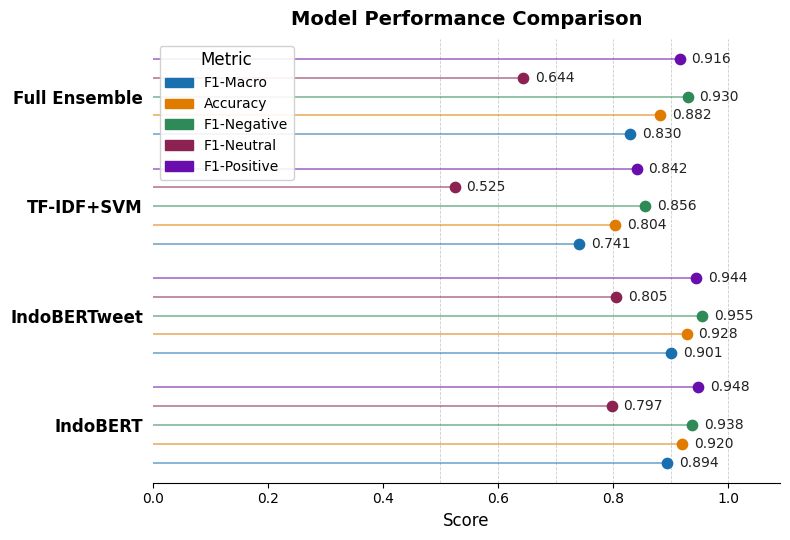

Saved fig2_performance_comparison_updated.png


In [4]:
# ── Data ─────────────────────────────────────────────────────────────────────
MODELS   = ['IndoBERT', 'IndoBERTweet', 'TF-IDF+SVM', 'Full Ensemble']
METRICS  = ['f1_macro', 'accuracy', 'f1_negative', 'f1_neutral', 'f1_positive']
MLABELS  = ['F1-Macro', 'Accuracy', 'F1-Negative', 'F1-Neutral', 'F1-Positive']

# Sort so Full Ensemble is last (bottom in horizontal chart)
df_fig2 = metrics_df.set_index('model').loc[MODELS][METRICS].reset_index()

# Color palette — one color per metric
METRIC_COLORS = ['#1a6faf', '#e07b00', '#2e8b57', '#8b2252', '#6a0dad']

# ── Layout ───────────────────────────────────────────────────────────────────
n_models  = len(MODELS)
n_metrics = len(METRICS)
gap       = 0.15   # gap between model groups
step      = 0.18   # vertical step between dots in one group

fig, ax = plt.subplots(figsize=(8, 5.5))

ytick_positions = []
ytick_labels    = []

for mi, model in enumerate(MODELS):
    row      = df_fig2[df_fig2['model'] == model].iloc[0]
    y_center = mi * (n_metrics * step + gap)

    for ki, (met, col) in enumerate(zip(METRICS, METRIC_COLORS)):
        y_pos = y_center + ki * step
        val   = row[met]

        # Lollipop stem
        ax.plot([0, val], [y_pos, y_pos], color=col, linewidth=1.2, alpha=0.6)
        # Dot
        ax.scatter(val, y_pos, color=col, s=55, zorder=4)
        # Annotation
        ax.text(val + 0.02, y_pos, f'{val:.3f}',
                va='center', ha='left', fontsize=10, color='#222222')

    # Model label position: middle of the group
    ytick_positions.append(y_center + (n_metrics - 1) * step / 2)
    ytick_labels.append(model)

ax.set_yticks(ytick_positions)
ax.set_yticklabels(ytick_labels, fontsize=12, fontweight='bold')
ax.set_xlabel('Score', fontsize=12)
ax.set_xlim(0, 1.09)
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold', pad=10)

# Reference lines
for xv in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    ax.axvline(xv, color='#cccccc', linewidth=0.6, linestyle='--', zorder=0)

# Legend
legend_handles = [
    mpatches.Patch(color=col, label=lbl)
    for col, lbl in zip(METRIC_COLORS, MLABELS)
]
ax.legend(handles=legend_handles, title='Metric', title_fontsize=12,
          fontsize=10, loc='upper left', framealpha=0.9,
          edgecolor='#cccccc')

ax.spines['left'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(left=False)

plt.tight_layout()
plt.savefig('outputs/figures/fig2_performance_comparison_updated.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved fig2_performance_comparison_updated.png')

## Figure 3 — Confusion Matrices (2×2 Grid)

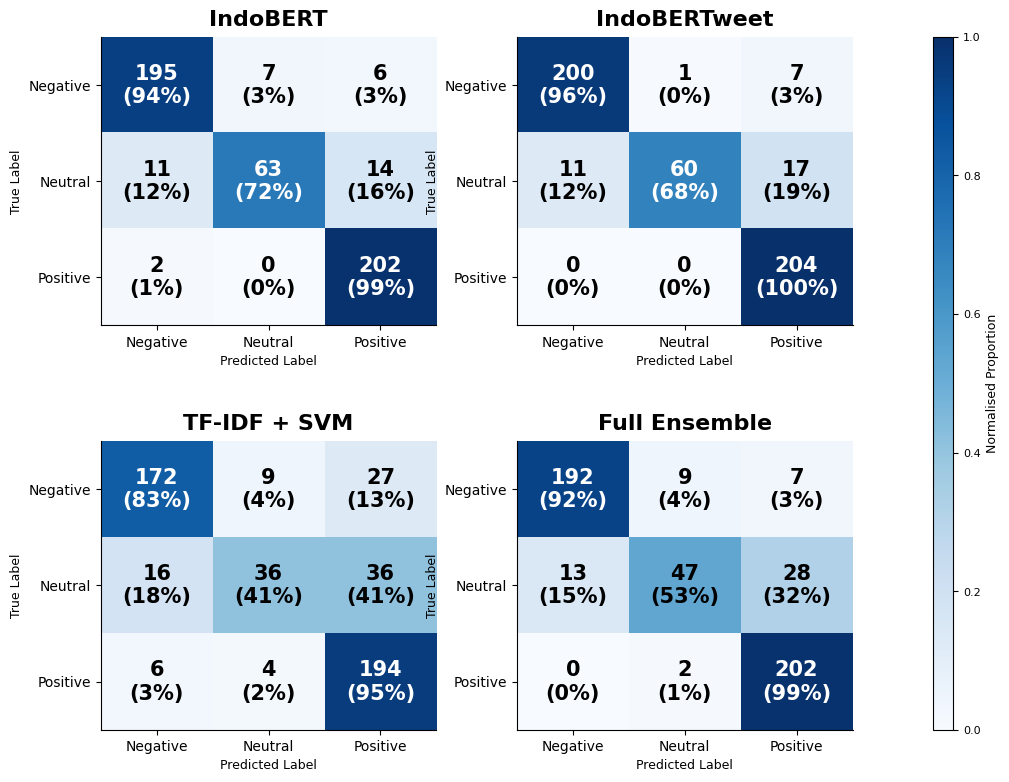

Saved fig3_confusion_matrices_2x2_updated.png


In [7]:
# ── Data ─────────────────────────────────────────────────────────────────────
MODEL_PREDS = [
    ('IndoBERT',       pred_indobert),
    ('IndoBERTweet',   pred_indobertweet),
    ('TF-IDF + SVM',   pred_svm),
    ('Full Ensemble',  pred_ensemble),
]

# ── Build confusion matrices in Negative / Neutral / Positive order ───────────
# LABEL2ID = positive:0, neutral:1, negative:2 → reorder to neg(2), neu(1), pos(0)
def build_cm(y_true, y_pred, order):
    cm = confusion_matrix(y_true, y_pred)  # shape (3,3) in LABEL2ID order
    cm = cm[np.ix_(order, order)]          # reorder rows and cols
    return cm

ORDER = DISP_ORDER  # [2, 1, 0]  → Negative, Neutral, Positive

cms = [(name, build_cm(y_true, preds, ORDER)) for name, preds in MODEL_PREDS]

# ── Global vmax across all matrices for consistent color scale ────────────────
all_cmn = []
for _, cm in cms:
    cmn = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    all_cmn.append(cmn)

vmin, vmax = 0.0, 1.0

# ── Figure ───────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(11, 9))
gs  = GridSpec(2, 3, figure=fig,
               width_ratios=[1, 1, 0.06],   # last col for shared colorbar
               hspace=0.40, wspace=0.35)

axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
]
cbar_ax = fig.add_subplot(gs[:, 2])

im_ref = None
for ax, (name, cm) in zip(axes, cms):
    cmn = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    im = ax.imshow(cmn, cmap='Blues', vmin=vmin, vmax=vmax, aspect='auto')
    im_ref = im

    # Tick labels
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(CLASS_NAMES, fontsize=10)
    ax.set_yticklabels(CLASS_NAMES, fontsize=10)
    ax.set_xlabel('Predicted Label', fontsize=9)
    ax.set_ylabel('True Label', fontsize=9)
    ax.set_title(name, fontsize=16, fontweight='bold', pad=8)

    # Cell annotations: count + normalised %
    for i in range(3):
        for j in range(3):
            count = cm[i, j]
            norm  = cmn[i, j]
            txt_color = 'white' if norm > 0.55 else 'black'
            ax.text(j, i,
                    f'{count}\n({norm:.0%})',
                    ha='center', va='center',
                    fontsize=15, fontweight='bold', color=txt_color)

# Shared colorbar
cbar = fig.colorbar(im_ref, cax=cbar_ax)
cbar.set_label('Normalised Proportion', fontsize=9)
cbar.ax.tick_params(labelsize=8)

# fig.suptitle('Confusion Matrices — All Models', fontsize=13, fontweight='bold', y=1.01)

plt.savefig('outputs/figures/fig3_confusion_matrices_2x2_updated.png',
            dpi=300, bbox_inches='tight')
plt.show()
print('Saved fig3_confusion_matrices_2x2_updated.png')

## Figure 8 — Ablation Study: Component Contribution (Horizontal Bar + Reference Line)

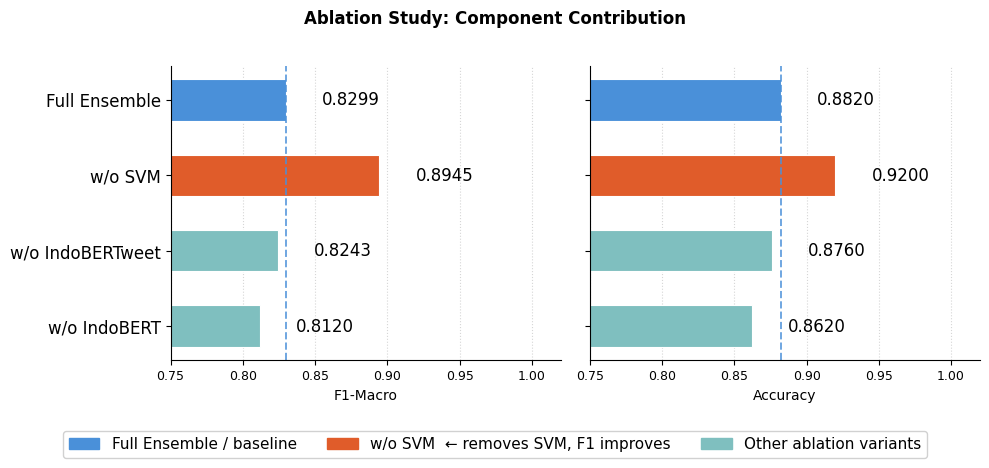

Saved fi8_ablation_comparison_updated.png


In [6]:
# ── Data ─────────────────────────────────────────────────────────────────────
# Display order: Full Ensemble at top, then ablation variants below
ABL_ORDER = ['Full Ensemble', 'w/o SVM', 'w/o IndoBERTweet', 'w/o IndoBERT']
df_abl = ablation_df.set_index('model').loc[ABL_ORDER, ['f1_macro', 'accuracy']].reset_index()

# Full Ensemble baseline values (for reference line)
baseline_f1  = df_abl.loc[df_abl['model'] == 'Full Ensemble', 'f1_macro'].values[0]
baseline_acc = df_abl.loc[df_abl['model'] == 'Full Ensemble', 'accuracy'].values[0]

# ── Layout: two side-by-side panels ──────────────────────────────────────────
fig, (ax_f1, ax_acc) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

# Color: highlight 'w/o SVM' (improves F1) in a distinct accent color
BAR_COLORS = {
    'Full Ensemble':    '#4a90d9',
    'w/o SVM':          '#e05c2a',   # accent — this one *improves* F1
    'w/o IndoBERTweet': '#7fbfbf',
    'w/o IndoBERT':     '#7fbfbf',
}

models   = df_abl['model'].tolist()
f1_vals  = df_abl['f1_macro'].tolist()
acc_vals = df_abl['accuracy'].tolist()
y_pos    = range(len(models))
colors   = [BAR_COLORS[m] for m in models]

def draw_panel(ax, values, baseline, xlabel):
    bars = ax.barh(list(y_pos), values, color=colors,
                   height=0.55, edgecolor='white', linewidth=0.8)

    # Reference line: Full Ensemble baseline
    ax.axvline(baseline, color='#4a90d9', linewidth=1.4,
               linestyle='--', alpha=0.8, label=f'Full Ensemble ({baseline:.4f})')

    # Value annotations
    for bar, val in zip(bars, values):
        ax.text(val + 0.025, bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', ha='left', fontsize=12)

    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_xlim(0.75, 1.02)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=9)

    # Light gridlines
    ax.xaxis.grid(True, linestyle=':', alpha=0.4, color='#999999')
    ax.set_axisbelow(True)

draw_panel(ax_f1,  f1_vals,  baseline_f1,  'F1-Macro')
draw_panel(ax_acc, acc_vals, baseline_acc, 'Accuracy')

# Y-axis labels only on left panel (sharey)
ax_f1.set_yticks(list(y_pos))
ax_f1.set_yticklabels(models, fontsize=12)
ax_f1.invert_yaxis()   # Full Ensemble at top

# Shared legend
legend_handles = [
    mpatches.Patch(color='#4a90d9', label='Full Ensemble / baseline'),
    mpatches.Patch(color='#e05c2a', label='w/o SVM  ← removes SVM, F1 improves'),
    mpatches.Patch(color='#7fbfbf', label='Other ablation variants'),
]
fig.legend(handles=legend_handles, fontsize=11, loc='lower center',
           ncol=3, bbox_to_anchor=(0.5, -0.12), framealpha=0.9,
           edgecolor='#cccccc')

fig.suptitle('Ablation Study: Component Contribution', fontsize=12,
             fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('outputs/figures/fi8_ablation_comparison_updated.png',
            dpi=300, bbox_inches='tight')
plt.show()
print('Saved fi8_ablation_comparison_updated.png')

---
### Summary of saved figures
| Figure | File |
|--------|------|
| Fig 2  | `outputs/figures/fig2_performance_comparison_updated.png` |
| Fig 3  | `outputs/figures/fig3_confusion_matrices_2x2_updated.png` |
| Fig 8  | `outputs/figures/fi8_ablation_comparison_updated.png` |